# 06 Convergence experiment

The deployed `char_balanced` model comes from notebook 02, where the saga solver stops at 220 iterations, and for the class-weighted model it stops there before converging. This notebook asks what changes when the three linear systems are fitted to convergence instead. L-BFGS minimises the same regularised loss to its minimum, over a wider C grid ({0.25, 1, 4, ..., 16384}, a factor of 4 apart), and every choice is made on development macro-F1 by the same rules as notebooks 02 and 04.

It does not change the deployed system. It scores the test split a second time, after the first release had already been scored, and the decision to keep `char_balanced` deployed was made after seeing both test scores. [docs/results.md](../docs/results.md#a-second-test-scoring) reports the outcome.

With `RETRAIN = False` the notebook shows the saved results in `results/convergence.json`. With True it fits the grid again, which takes about six minutes on a laptop.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Keaane/Ikinyamakuru/blob/main/notebooks/06_convergence.ipynb)

In [1]:
# Setup: run from the repository root, on a laptop or on Colab.
import os
import subprocess
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/Ikinyamakuru").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Keaane/Ikinyamakuru.git", "/content/Ikinyamakuru"], check=True)
    os.chdir("/content/Ikinyamakuru")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))

# Show each warning as one short line.
warnings.showwarning = lambda message, category, *args, **kwargs: print(f"{category.__name__}: {message}")

In [2]:
RETRAIN = False  # True fits the grid again and overwrites results/convergence.json and its figure

In [3]:
import json
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from inkuru.data import load_split
from inkuru.labels import LABELS
from inkuru.metrics import choose_threshold, classification_scores, coverage_stats
from inkuru.paths import FIGURES, RESULTS

CS = [0.25, 1.0, 4.0, 16.0, 64.0, 256.0, 1024.0, 4096.0, 16384.0]
MAX_ITER = 5000  # a cap only; every fit must converge before it
OUT = RESULTS / "convergence.json"

## Fit to convergence

The features are notebook 02's. For each feature set the C with the best development macro-F1 is kept, and the class-weighted model reuses the character model's C, as in notebook 02. The test split is scored for every fit so the figure below can show it, but no choice reads those scores.

In [4]:
def fit(estimator, features, labels) -> int:
    """Fit and return the iteration count, or stop if the solver hit MAX_ITER before converging."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        estimator.fit(features, labels)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise RuntimeError(f"{estimator} stopped at max_iter={MAX_ITER} before converging")
    return int(estimator.n_iter_.max())


def vectorizer(word: bool) -> TfidfVectorizer:
    if word:
        return TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=80000, sublinear_tf=True)


def predict(clf, features) -> tuple[list[str], np.ndarray]:
    """The top section and its score for every article."""
    proba = clf.predict_proba(features)
    return [str(clf.classes_[i]) for i in proba.argmax(axis=1)], proba.max(axis=1)


if RETRAIN:
    splits = {name: load_split(name) for name in ("train", "dev", "test")}
    text = {name: [row["text"] for row in rows] for name, rows in splits.items()}
    gold = {name: [row["label"] for row in rows] for name, rows in splits.items()}
    runs, features = {}, {}
    for name, word in (("word", True), ("char", False)):
        vec = vectorizer(word)
        X = {"train": vec.fit_transform(text["train"]), "dev": vec.transform(text["dev"]), "test": vec.transform(text["test"])}
        features[name] = X
        grid, best = {}, None
        for C in CS:
            start = time.time()
            clf = LogisticRegression(C=C, solver="lbfgs", max_iter=MAX_ITER)
            iterations = fit(clf, X["train"], gold["train"])
            dev, test = predict(clf, X["dev"]), predict(clf, X["test"])
            dev_scores = classification_scores(gold["dev"], dev[0])
            grid[str(C)] = {"iterations": iterations, "dev_macro_f1": dev_scores["macro_f1"], "dev_accuracy": dev_scores["accuracy"],
                            "test_macro_f1": classification_scores(gold["test"], test[0])["macro_f1"]}
            print(f"{name:5s} C={C:<8} {iterations:4d} iterations  development macro-F1 {dev_scores['macro_f1']:.4f}  {time.time() - start:3.0f}s")
            if best is None or dev_scores["macro_f1"] > best["dev_macro_f1"]:
                best = {"C": C, "iterations": iterations, "dev_macro_f1": dev_scores["macro_f1"], "dev": dev, "test": test}
        runs[name] = {**best, "grid": grid}
    C = runs["char"]["C"]
    clf = LogisticRegression(C=C, solver="lbfgs", max_iter=MAX_ITER, class_weight="balanced")
    iterations = fit(clf, features["char"]["train"], gold["train"])
    runs["char_balanced"] = {"C": C, "iterations": iterations,
                             "dev": predict(clf, features["char"]["dev"]), "test": predict(clf, features["char"]["test"])}

    systems = {}
    for name, run in runs.items():
        dev_scores = classification_scores(gold["dev"], run["dev"][0])
        test_scores = classification_scores(gold["test"], run["test"][0])
        systems[name] = {
            "C": run["C"],
            "iterations": run["iterations"],
            "dev": {key: dev_scores[key] for key in ("accuracy", "macro_precision", "macro_recall", "macro_f1")},
            "test": {key: test_scores[key] for key in ("accuracy", "macro_precision", "macro_recall", "macro_f1")},
            "test_f1_by_section": {label: test_scores["per_class"][label]["f1"] for label in LABELS},
            "test_recall_by_section": {label: test_scores["per_class"][label]["recall"] for label in LABELS},
            "test_filed_by_section": {label: int(sum(pred == label for pred in run["test"][0])) for label in LABELS},
            "mean_top_score": {"dev": float(np.mean(run["dev"][1])), "test": float(np.mean(run["test"][1]))},
            "grid": run.get("grid"),
        }
    winner = max(systems, key=lambda name: systems[name]["dev"]["macro_f1"])
    threshold = choose_threshold(gold["dev"], runs[winner]["dev"][0], runs[winner]["dev"][1])
    report = {
        "solver": "lbfgs",
        "max_iter": MAX_ITER,
        "C_grid": CS,
        "selected_on_development": winner,
        "threshold": threshold,
        "test_filing": coverage_stats(gold["test"], runs[winner]["test"][0], runs[winner]["test"][1], threshold["threshold"]),
        "systems": systems,
    }
    OUT.write_text(json.dumps(report, indent=2) + "\n")

report = json.loads(OUT.read_text())

## The choice on development

Every fit converged well before the cap. The development choice follows notebook 04's rule among the three linear systems; the encoder runs score lower on development (0.488 at best), so they would not change it.

In [5]:
for name, run in report["systems"].items():
    if run["grid"]:
        print(f"{name}:")
        for C, row in run["grid"].items():
            mark = "  <- chosen" if float(C) == run["C"] else ""
            print(f"   C={float(C):<8g} {row['iterations']:4d} iterations  development macro-F1 {row['dev_macro_f1']:.4f}{mark}")
print(f"char_balanced: C={report['systems']['char_balanced']['C']:g} (the char model's C), {report['systems']['char_balanced']['iterations']} iterations")
winner = report["selected_on_development"]
threshold = report["threshold"]
print(f"\nselected {winner}; cutoff {threshold['threshold']}, files {threshold['coverage']:.1%} of development, "
      f"{threshold['accuracy_kept']:.1%} of those correct")

word:
   C=0.25       53 iterations  development macro-F1 0.3736
   C=1          77 iterations  development macro-F1 0.5086
   C=4         104 iterations  development macro-F1 0.5397
   C=16        112 iterations  development macro-F1 0.5860
   C=64        120 iterations  development macro-F1 0.6145
   C=256       102 iterations  development macro-F1 0.6350
   C=1024       74 iterations  development macro-F1 0.6453
   C=4096       60 iterations  development macro-F1 0.6702  <- chosen
   C=16384      58 iterations  development macro-F1 0.6669
char:
   C=0.25       52 iterations  development macro-F1 0.3687
   C=1          89 iterations  development macro-F1 0.5206
   C=4         115 iterations  development macro-F1 0.5496
   C=16        139 iterations  development macro-F1 0.6312
   C=64        142 iterations  development macro-F1 0.6869
   C=256       133 iterations  development macro-F1 0.7196
   C=1024       97 iterations  development macro-F1 0.7100
   C=4096       83 iterations  de

## The test split, after the fact

The first release's scores come from `results/metrics.json` and its per-article predictions; its solver stopped at 220 iterations with C = 16. The mean top-section score shows how sure each model is, and the last table counts how often each model puts a test article under each section.

In [6]:
first = json.loads((RESULTS / "metrics.json").read_text())


def mean_top(name: str, split: str) -> float:
    with (RESULTS / f"{name}_{split}.jsonl").open(encoding="utf-8") as handle:
        return float(np.mean([json.loads(line)["confidence"] for line in handle]))


print(f"{'system':15s}{'':12s}{'dev F1':>8s}{'test acc':>10s}{'test F1':>9s}{'mean top score (test)':>24s}")
for name in ("word", "char", "char_balanced"):
    old, new = first["systems"][name], report["systems"][name]
    print(f"{name:15s}{'first':12s}{old['dev']['macro_f1']:8.3f}{old['test']['accuracy']:10.3f}{old['test']['macro_f1']:9.3f}{mean_top(name, 'test'):24.3f}")
    print(f"{'':15s}{'converged':12s}{new['dev']['macro_f1']:8.3f}{new['test']['accuracy']:10.3f}{new['test']['macro_f1']:9.3f}{new['mean_top_score']['test']:24.3f}")

deployed, converged = first["systems"]["char_balanced"], report["systems"][winner]
print(f"\ndeployed char_balanced files {deployed['filing']['coverage']:.1%} of test and is right on {deployed['filing']['accuracy_kept']:.1%}")
print(f"converged {winner} would file {report['test_filing']['coverage']:.1%} and be right on {report['test_filing']['accuracy_kept']:.1%}")

print(f"\ntest F1 by section, deployed char_balanced against converged {winner}:")
for label in sorted(LABELS, key=lambda label: converged["test_f1_by_section"][label] - deployed["per_class"][label]["f1"]):
    before, after = deployed["per_class"][label]["f1"], converged["test_f1_by_section"][label]
    print(f"   {label:13s} {before:.3f} -> {after:.3f}  ({after - before:+.3f})")

train_counts = Counter(row["label"] for row in load_split("train"))
test_counts = Counter(row["label"] for row in load_split("test"))
with (RESULTS / "char_balanced_test.jsonl").open(encoding="utf-8") as handle:
    deployed_filed = Counter(json.loads(line)["pred"] for line in handle)
print(f"\ntest articles put under each section, and recall, deployed char_balanced against converged {winner}:")
print(f"   {'section':13s}{'train':>7s}{'test':>6s}{'filed':>9s}{'':>6s}{'recall':>9s}")
for label in LABELS:
    print(f"   {label:13s}{train_counts[label]:7d}{test_counts[label]:6d}"
          f"{deployed_filed[label]:7d} ->{converged['test_filed_by_section'][label]:4d}"
          f"{deployed['per_class'][label]['recall']:9.2f} ->{converged['test_recall_by_section'][label]:5.2f}")

system                       dev F1  test acc  test F1   mean top score (test)
word           first          0.545     0.690    0.428                   0.717
               converged      0.670     0.700    0.479                   0.918
char           first          0.622     0.697    0.456                   0.740
               converged      0.736     0.683    0.485                   0.915
char_balanced  first          0.692     0.734    0.583                   0.743
               converged      0.666     0.683    0.462                   0.910

deployed char_balanced files 73.8% of test and is right on 84.7%
converged char would file 74.2% and be right on 79.1%

test F1 by section, deployed char_balanced against converged char:
   environment   0.561 -> 0.147  (-0.414)
   tourism       0.373 -> 0.145  (-0.228)
   history       0.326 -> 0.176  (-0.149)
   culture       0.447 -> 0.306  (-0.141)
   economy       0.621 -> 0.525  (-0.096)
   health        0.586 -> 0.507  (-0.079)
   tech


test articles put under each section, and recall, deployed char_balanced against converged char:
   section        train  test    filed         recall
   politics        1628   315    524 -> 455     0.83 -> 0.75
   sport            878   744    711 -> 746     0.92 -> 0.93
   economy         1000   174    232 -> 310     0.72 -> 0.73
   health           978   272    305 -> 403     0.62 -> 0.63
   entertainment    994   774    753 -> 779     0.80 -> 0.77
   history          196    11     32 ->  91     0.64 -> 0.82
   technology       136   103     98 ->  93     0.70 -> 0.61
   tourism           31    76     26 ->   7     0.25 -> 0.08
   culture           69   138     50 ->  32     0.30 -> 0.19
   fashion           34    91     86 ->  35     0.55 -> 0.35
   religion         401   256    198 -> 185     0.64 -> 0.61
   environment       34   100     64 ->   9     0.46 -> 0.08
   education        104    70     11 ->   9     0.04 -> 0.04
   relationship     381   340    374 -> 310     0.84 ->

## Development and test macro-F1 by C

Fitted to convergence, a weaker penalty (larger C) helps the unweighted models on both splits, so the converged fits are not worse in general. The gap is the class-weighted first release: it puts far more test articles under tourism, fashion, environment, and culture, sections the test file has two to three times as many of as the training file ([data/README.md](../data/README.md#split-sizes)). Development keeps the training file's mix, so it does not reward that, and at C = 4096 the class weights no longer help even on development.

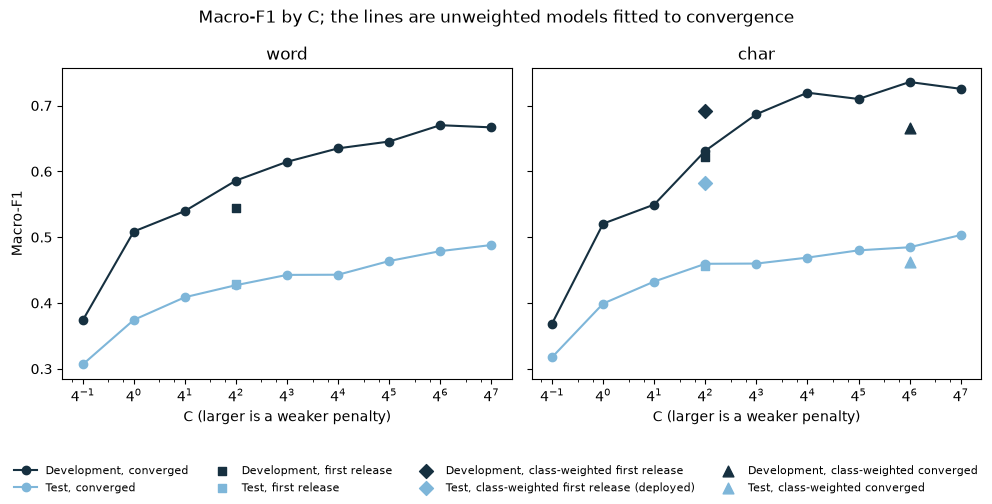

In [7]:
grid_first = json.loads((RESULTS / "baseline_grid.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, name in zip(axes, ("word", "char")):
    grid = report["systems"][name]["grid"]
    cs = [float(C) for C in grid]
    ax.plot(cs, [row["dev_macro_f1"] for row in grid.values()], marker="o", color="#163040", label="Development, converged")
    ax.plot(cs, [row["test_macro_f1"] for row in grid.values()], marker="o", color="#7eb6d9", label="Test, converged")
    C = grid_first[name]["C"]
    ax.scatter([C], [first["systems"][name]["dev"]["macro_f1"]], marker="s", color="#163040", zorder=3, label="Development, first release")
    ax.scatter([C], [first["systems"][name]["test"]["macro_f1"]], marker="s", color="#7eb6d9", zorder=3, label="Test, first release")
    if name == "char":
        balanced = report["systems"]["char_balanced"]
        ax.scatter([grid_first["char_balanced"]["C"]], [first["systems"]["char_balanced"]["dev"]["macro_f1"]], marker="D", s=50,
                   color="#163040", zorder=3, label="Development, class-weighted first release")
        ax.scatter([grid_first["char_balanced"]["C"]], [first["systems"]["char_balanced"]["test"]["macro_f1"]], marker="D", s=50,
                   color="#7eb6d9", zorder=3, label="Test, class-weighted first release (deployed)")
        ax.scatter([balanced["C"]], [balanced["dev"]["macro_f1"]], marker="^", s=60, color="#163040", zorder=3,
                   label="Development, class-weighted converged")
        ax.scatter([balanced["C"]], [balanced["test"]["macro_f1"]], marker="^", s=60, color="#7eb6d9", zorder=3,
                   label="Test, class-weighted converged")
    ax.set_xscale("log", base=4)
    ax.set_xlabel("C (larger is a weaker penalty)")
    ax.set_title(f"{name}")
axes[0].set_ylabel("Macro-F1")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.suptitle("Macro-F1 by C; the lines are unweighted models fitted to convergence")
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig(FIGURES / "convergence.png", dpi=160)
plt.show()